In [1]:
import os, random, json, time, numpy as np, pandas as pd
import torch, torch.nn as nn, torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, Subset
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

DATA_DIR = "/kaggle/input/datasets/freshwater-fish-dataset/Freshwater Fish Disease Aquaculture in south asia"
TRAIN_DIR = os.path.join(DATA_DIR, "Train")
TEST_DIR  = os.path.join(DATA_DIR, "Test")
OUT = "/kaggle/working"
os.makedirs(f"{OUT}/ckpt", exist_ok=True); os.makedirs(f"{OUT}/preds", exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")
print(os.listdir(DATA_DIR))   # should show Train and Test

# ---- settings (report exactly these in the paper) ----
BATCH = 16; EPOCHS = 30; LR = 3e-5; WD = 1e-4; SPLIT_SEED = 42
MEAN, STD = [0.485,0.456,0.406], [0.229,0.224,0.225]

train_tf = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose([
    transforms.Resize((224,224)), transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

Device: cuda Tesla T4
['Test', 'Train']


In [2]:
ds_train_aug = datasets.ImageFolder(TRAIN_DIR, transform=train_tf)   # augmented
ds_train_eval = datasets.ImageFolder(TRAIN_DIR, transform=eval_tf)   # same files, no augmentation
test_ds = datasets.ImageFolder(TEST_DIR, transform=eval_tf)
class_names = ds_train_aug.classes
assert class_names == test_ds.classes
print(class_names, len(ds_train_aug), len(test_ds))

g = torch.Generator().manual_seed(SPLIT_SEED)
perm = torch.randperm(len(ds_train_aug), generator=g).tolist()
n_train = int(0.8*len(perm))
train_idx, val_idx = perm[:n_train], perm[n_train:]
print("train/val:", len(train_idx), len(val_idx))

train_set = Subset(ds_train_aug, train_idx)     # augmentation ON
val_set   = Subset(ds_train_eval, val_idx)      # augmentation OFF

def loaders():
    return (DataLoader(train_set, BATCH, shuffle=True, num_workers=2, pin_memory=True),
            DataLoader(val_set, BATCH, shuffle=False, num_workers=2, pin_memory=True),
            DataLoader(test_ds, BATCH, shuffle=False, num_workers=2, pin_memory=True))

['Bacterial Red disease', 'Bacterial diseases - Aeromoniasis', 'Bacterial gill disease', 'Fungal diseases Saprolegniasis', 'Healthy Fish', 'Parasitic diseases', 'Viral diseases White tail disease'] 1750 700
train/val: 1400 350


In [3]:
def build(name, nc=len(class_names), pretrained=True):
    w = "DEFAULT" if pretrained else None
    if name == "efficientnet_b0":
        m = models.efficientnet_b0(weights=w); m.classifier[1] = nn.Linear(m.classifier[1].in_features, nc)
    elif name == "resnet152":
        m = models.resnet152(weights=w); m.fc = nn.Linear(m.fc.in_features, nc)
    elif name == "densenet121":
        m = models.densenet121(weights=w); m.classifier = nn.Linear(m.classifier.in_features, nc)
    return m.to(device)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

@torch.no_grad()
def predict(model, loader):
    model.eval(); P, Y = [], []
    for x, y in loader:
        P.append(torch.softmax(model(x.to(device)), 1).cpu().numpy()); Y.append(y.numpy())
    return np.concatenate(P), np.concatenate(Y)

def run(name, seed):
    set_seed(seed)
    tr, va, te = loaders()
    model = build(name)
    opt = optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)
    sch = optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=3)
    crit = nn.CrossEntropyLoss()
    best, best_ep, hist = 0, 0, []
    ck = f"{OUT}/ckpt/{name}_s{seed}.pth"
    for ep in range(EPOCHS):
        model.train(); tl = 0
        for x, y in tr:
            x, y = x.to(device), y.to(device)
            opt.zero_grad(); loss = crit(model(x), y); loss.backward(); opt.step(); tl += loss.item()
        p, y = predict(model, va); va_acc = (p.argmax(1)==y).mean()
        sch.step(va_acc); hist.append((ep+1, tl/len(tr), va_acc))
        if va_acc > best:
            best, best_ep = va_acc, ep+1; torch.save(model.state_dict(), ck)
    model.load_state_dict(torch.load(ck, map_location=device))
    p, y = predict(model, te)
    np.save(f"{OUT}/preds/{name}_s{seed}_probs.npy", p); np.save(f"{OUT}/preds/test_labels.npy", y)
    acc = (p.argmax(1)==y).mean()
    print(f"{name} seed {seed}: best val {best:.4f} (epoch {best_ep}) | TEST {acc*100:.2f}%")
    return dict(model=name, seed=seed, val=best, best_epoch=best_ep, test=acc)

In [4]:
results = []
for s in [1,2,3,4,5]:       results.append(run("efficientnet_b0", s))
for s in [1,2,3]:           results.append(run("resnet152", s))
for s in [1,2,3]:           results.append(run("densenet121", s))
df = pd.DataFrame(results); df.to_csv(f"{OUT}/seed_results.csv", index=False)
summary = df.groupby("model")[["val","test"]].agg(["mean","std"]); print(summary*100)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 196MB/s]


efficientnet_b0 seed 1: best val 0.9629 (epoch 25) | TEST 99.00%
efficientnet_b0 seed 2: best val 0.9657 (epoch 24) | TEST 99.14%
efficientnet_b0 seed 3: best val 0.9600 (epoch 30) | TEST 99.14%
efficientnet_b0 seed 4: best val 0.9600 (epoch 26) | TEST 99.29%
efficientnet_b0 seed 5: best val 0.9629 (epoch 26) | TEST 99.43%
Downloading: "https://download.pytorch.org/models/resnet152-f82ba261.pth" to /root/.cache/torch/hub/checkpoints/resnet152-f82ba261.pth


100%|██████████| 230M/230M [00:01<00:00, 168MB/s]  


resnet152 seed 1: best val 0.9743 (epoch 13) | TEST 99.43%
resnet152 seed 2: best val 0.9657 (epoch 14) | TEST 99.14%
resnet152 seed 3: best val 0.9714 (epoch 13) | TEST 99.43%
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 182MB/s]


densenet121 seed 1: best val 0.9629 (epoch 17) | TEST 99.29%
densenet121 seed 2: best val 0.9600 (epoch 28) | TEST 99.29%
densenet121 seed 3: best val 0.9657 (epoch 16) | TEST 99.14%
                       val                 test          
                      mean       std       mean       std
model                                                    
densenet121      96.285714  0.285714  99.238095  0.082479
efficientnet_b0  96.228571  0.239046  99.200000  0.162882
resnet152        97.047619  0.436436  99.333333  0.164957


In [7]:
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.proportion import proportion_confint
y = np.load(f"{OUT}/preds/test_labels.npy")
L = lambda n,s: np.load(f"{OUT}/preds/{n}_s{s}_probs.npy")

for s in [1,2,3]:
    ens = (L("efficientnet_b0",s)+L("resnet152",s))/2
    b0, ens_c = L("efficientnet_b0",s).argmax(1)==y, ens.argmax(1)==y
    tab = [[(b0&ens_c).sum(), (b0&~ens_c).sum()],[(~b0&ens_c).sum(), (~b0&~ens_c).sum()]]
    p = mcnemar(tab, exact=True).pvalue
    lo,hi = proportion_confint(ens_c.sum(), len(y), method="wilson")
    print(f"seed {s}: B0 {b0.mean()*100:.2f}% | ensemble {ens_c.mean()*100:.2f}% [{lo*100:.2f},{hi*100:.2f}] | McNemar p={p:.3f}")

# class-wise report for B0 seed 1
print(classification_report(y, L("efficientnet_b0",1).argmax(1), target_names=class_names, digits=4))

seed 1: B0 99.00% | ensemble 99.29% [98.34,99.69] | McNemar p=0.500
seed 2: B0 99.14% | ensemble 99.14% [98.14,99.61] | McNemar p=1.000
seed 3: B0 99.14% | ensemble 99.43% [98.54,99.78] | McNemar p=0.500
                                   precision    recall  f1-score   support

            Bacterial Red disease     0.9901    1.0000    0.9950       100
Bacterial diseases - Aeromoniasis     0.9898    0.9700    0.9798       100
           Bacterial gill disease     0.9804    1.0000    0.9901       100
   Fungal diseases Saprolegniasis     1.0000    0.9800    0.9899       100
                     Healthy Fish     0.9900    0.9900    0.9900       100
               Parasitic diseases     0.9804    1.0000    0.9901       100
Viral diseases White tail disease     1.0000    0.9900    0.9950       100

                         accuracy                         0.9900       700
                        macro avg     0.9901    0.9900    0.9900       700
                     weighted avg     0.9901

test images with a train neighbour cosine>0.9: 700
test images with a train neighbour cosine>0.95: 700
test images with a train neighbour cosine>0.98: 700
removed 700 -> B0 acc on 0 images: nan ± nan


/tmp/ipykernel_50/406313731.py:15: RuntimeWarning: Mean of empty slice.
  accs = [ (L("efficientnet_b0",s).argmax(1)==y)[~dup_mask].mean()*100 for s in range(1,6)]
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:147: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


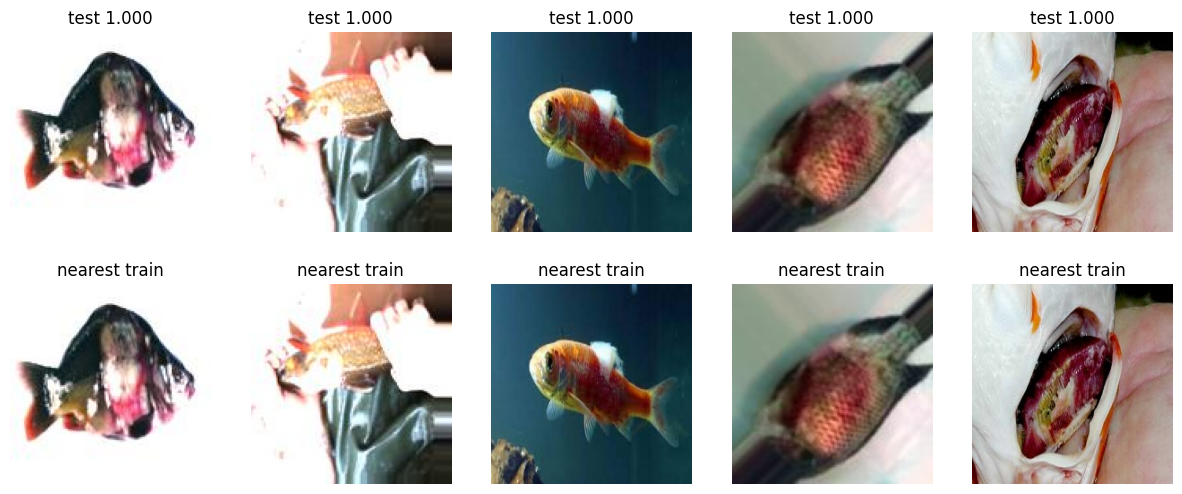

In [8]:
b0 = build("efficientnet_b0", pretrained=True); b0.classifier = nn.Identity(); b0.eval()  # ImageNet features
@torch.no_grad()
def feats(ds):
    dl = DataLoader(ds, 32, shuffle=False, num_workers=2); F=[]
    for x,_ in dl: F.append(torch.nn.functional.normalize(b0(x.to(device)),dim=1).cpu())
    return torch.cat(F)
Ftr, Fte = feats(ds_train_eval), feats(test_ds)
sim = Fte @ Ftr.T
mx, arg = sim.max(1)
for t in [0.90, 0.95, 0.98]:
    print(f"test images with a train neighbour cosine>{t}: {(mx>t).sum().item()}")

dup_mask = (mx > 0.95).numpy()
# accuracy with suspected duplicates removed (B0 seed 1, and mean over 5 seeds)
accs = [ (L("efficientnet_b0",s).argmax(1)==y)[~dup_mask].mean()*100 for s in range(1,6)]
print(f"removed {dup_mask.sum()} -> B0 acc on {(~dup_mask).sum()} images: {np.mean(accs):.2f} ± {np.std(accs, ddof=1):.2f}")

# eyeball the top pairs
import matplotlib.pyplot as plt
top = mx.argsort(descending=True)[:5]
fig, ax = plt.subplots(2,5, figsize=(15,6))
for i,t in enumerate(top):
    ax[0,i].imshow(plt.imread(test_ds.samples[t][0])); ax[0,i].set_title(f"test {mx[t]:.3f}"); ax[0,i].axis("off")
    ax[1,i].imshow(plt.imread(ds_train_eval.samples[arg[t]][0])); ax[1,i].set_title("nearest train"); ax[1,i].axis("off")
plt.savefig(f"{OUT}/duplicates.png", dpi=300, bbox_inches="tight"); plt.show()

In [9]:
!pip install grad-cam -q

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [10]:
from pytorch_grad_cam import GradCAM
model = build("efficientnet_b0", pretrained=False)
model.load_state_dict(torch.load(f"{OUT}/ckpt/efficientnet_b0_s1.pth", map_location=device)); model.eval()
cam = GradCAM(model=model, target_layers=[model.features[-1]])
healthy = class_names.index([c for c in class_names if "Healthy" in c][0])

rows = []
dl = DataLoader(test_ds, 16, shuffle=False)
i = 0
for x, yb in dl:
    x = x.to(device)
    with torch.no_grad(): pr = torch.softmax(model(x),1)
    pred = pr.argmax(1).cpu().numpy()
    from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
    maps = cam(input_tensor=x, targets=[ClassifierOutputTarget(int(k)) for k in pred])
    for j in range(len(x)):
        m = maps[j]
        rows.append(dict(idx=i, true=int(yb[j]), pred=int(pred[j]), conf=float(pr[j].max()),
                         **{f"a{int(t*100)}": 100*(m>=t).mean() for t in [0.3,0.4,0.5,0.6,0.7]}))
        i += 1
cdf = pd.DataFrame(rows); cdf["cls"] = [class_names[k] for k in cdf["pred"]]
cdf.to_csv(f"{OUT}/gradcam_areas.csv", index=False)

# 1) healthy-baseline: area for healthy images (CAM of their own predicted class) vs diseased
print(cdf.groupby(cdf["pred"]==healthy)["a50"].describe())
print(cdf.groupby("cls")["a50"].agg(["mean","std"]).round(2))
# 2) severity tiers under different cut-offs (diseased only)
d = cdf[cdf["pred"]!=healthy]
for lo,hi in [(5,15),(10,20),(10,25),(15,30)]:
    t = pd.cut(d["a50"], [-1,lo,hi,101], labels=["Mild","Moderate","Severe"]).value_counts()
    print((lo,hi), dict(t))
# 3) correlation between area and confidence
print("corr(area, conf):", d[["a50","conf"]].corr().iloc[0,1].round(3))

       count       mean       std       min       25%        50%        75%  \
pred                                                                          
False  600.0  12.487394  3.800679  5.992905  9.595723  11.874203  14.520388   
True   100.0  11.205875  3.595809  6.319754  8.633610  10.588728  12.543347   

             max  
pred              
False  30.454799  
True   26.203763  
                                    mean   std
cls                                           
Bacterial Red disease              12.39  4.23
Bacterial diseases - Aeromoniasis  11.98  3.83
Bacterial gill disease             12.31  3.83
Fungal diseases Saprolegniasis     11.32  3.33
Healthy Fish                       11.21  3.60
Parasitic diseases                 13.78  3.52
Viral diseases White tail disease  13.09  3.58
(5, 15) {'Moderate': np.int64(461), 'Severe': np.int64(139), 'Mild': np.int64(0)}
(10, 20) {'Moderate': np.int64(395), 'Mild': np.int64(175), 'Severe': np.int64(30)}
(10, 25) {'Moderat

In [12]:
from PIL import ImageFilter, ImageEnhance
import torchvision.transforms.functional as TF
class Perturbed(torch.utils.data.Dataset):
    def __init__(self, base, fn): self.base, self.fn = base, fn
    def __len__(self): return len(self.base)
    def __getitem__(self, i):
        p, lab = self.base.samples[i]
        from PIL import Image
        im = self.fn(Image.open(p).convert("RGB")); return eval_tf(im), lab
def noise(im):
    a = np.array(im).astype(np.float32); a += np.random.RandomState(0).normal(0,15,a.shape); return Image.fromarray(np.clip(a,0,255).astype(np.uint8))
def cast(im):
    a = np.array(im).astype(np.float32); a[...,1]*=0.8; a[...,2]*=0.8; return Image.fromarray(np.clip(a,0,255).astype(np.uint8))   # reddish/green-brown cast
def turbid(im):   # low contrast + haze
    im = ImageEnhance.Contrast(im).enhance(0.6); return Image.blend(im, Image.new("RGB", im.size, (150,160,140)), 0.3)
perturb = {"clean":lambda i:i, "dark":lambda i:ImageEnhance.Brightness(i).enhance(0.5), "bright":lambda i:ImageEnhance.Brightness(i).enhance(1.6),
           "blur":lambda i:i.filter(ImageFilter.GaussianBlur(3)), "noise":noise, "colour_cast":cast, "turbid":turbid}
from PIL import Image
out=[]
for s in range(1,6):
    m = build("efficientnet_b0", pretrained=False); m.load_state_dict(torch.load(f"{OUT}/ckpt/efficientnet_b0_s{s}.pth", map_location=device))
    for k,fn in perturb.items():
        p,yy = predict(m, DataLoader(Perturbed(test_ds,fn), 32, num_workers=2)); out.append((k,s,(p.argmax(1)==yy).mean()*100))
rb = pd.DataFrame(out, columns=["perturbation","seed","acc"]).groupby("perturbation")["acc"].agg(["mean","std"]).round(2)
print(rb); rb.to_csv(f"{OUT}/robustness.csv")

               mean   std
perturbation             
blur          74.09  1.48
bright        97.03  0.33
clean         99.20  0.16
colour_cast   98.74  0.12
dark          97.00  1.05
noise         63.71  2.15
turbid        93.00  1.67


In [14]:
def ece(p, y, bins=15):
    conf, pred = p.max(1), p.argmax(1); e=0
    for lo,hi in zip(np.linspace(0,1,bins+1)[:-1], np.linspace(0,1,bins+1)[1:]):
        m=(conf>lo)&(conf<=hi)
        if m.any(): e += m.mean()*abs((pred[m]==y[m]).mean()-conf[m].mean())
    return e
print("ECE (B0 seeds 1-5):", [round(ece(L("efficientnet_b0",s), y),4) for s in range(1,6)])

ECE (B0 seeds 1-5): [np.float64(0.012), np.float64(0.0099), np.float64(0.0094), np.float64(0.0118), np.float64(0.0105)]
